In [1]:
import numpy as np
import pandas as pd

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('../data/boat_vs_noise_audio_products.csv')

In [3]:
df['category'].value_counts()

category
True Wireless Earbuds    299
Neckband                 100
Headphones                70
Wired Earphones           43
Wired Headphones           6
Name: count, dtype: int64

In [5]:
df=df[df['category']=='True Wireless Earbuds']

In [7]:
df['brand'].value_counts()

brand
boAt     201
Noise     98
Name: count, dtype: int64

In [11]:
boat=df[df['brand']=='boAt']['sale_price']

In [12]:
Noise=df[df['brand']=='Noise']['sale_price']

In [9]:
df[df['brand']=='boAt']['sale_price'].var()

np.float64(750679.5179601989)

In [10]:
df[df['brand']=='Noise']['sale_price'].var()

np.float64(1270006.311803072)

1. Statistical Question

We want to investigate whether the average sale prices of boAt and Noise True Wireless Stereo (TWS) earbuds are significantly different.

Research Question: Is the average sale price of boAt TWS earbuds significantly different from that of Noise TWS earbuds?

In [17]:
boat_sample = boat.sample(n=50, random_state=42)
noise_sample = Noise.sample(n=50, random_state=42)

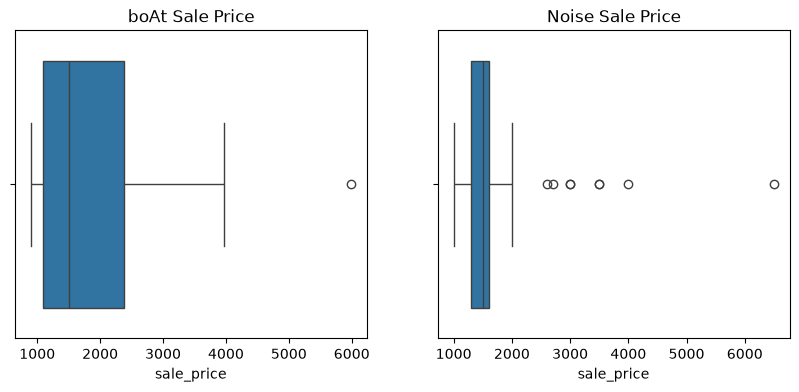

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(x=boat_sample, ax=axes[0])
axes[0].set_title("boAt Sale Price")

sns.boxplot(x=noise_sample, ax=axes[1])
axes[1].set_title("Noise Sale Price")

plt.show()

The boxplots showed some outliers in both groups. Since these values are genuine observations, they were retained rather than removed automatically.


2. Test Selection

We use an Independent Two-Sample t-Test because:

We are comparing the means of two independent groups: boAt and Noise.

The response variable, sale_price, is numerical.

The population standard deviations are unknown and estimated using sample standard deviations.

The two groups do not contain naturally paired observations.

We use the pooled version of the independent t-test because Levene's test did not provide sufficient evidence against the equal-variance assumption.

3. Hypotheses

Let:

μ₁ = Population mean sale price of boAt TWS earbuds.

μ₂ = Population mean sale price of Noise TWS earbuds.

Null Hypothesis (H₀):

μ₁ = μ₂

There is no difference between the population mean sale prices of boAt and Noise TWS earbuds.

Alternative Hypothesis (H₁):

μ₁ ≠ μ₂

The population mean sale prices of boAt and Noise TWS earbuds are different.

This is a two-tailed test because we are checking for a difference in either direction.

Assumptions

The independent two-sample t-test relies on the following assumptions:

Independence: Observations within and between the two groups should be independent.

Numerical variable: Sale price is a quantitative variable.

Random sampling: The samples should reasonably represent their respective populations.

Normality: Sale prices within each population should be approximately normally distributed, particularly for small samples.

Equal variances: The pooled Student's t-test assumes equal population variances.



In [19]:
print("boAt variance:", boat_sample.var())
print("Noise variance:", noise_sample.var())

print("boAt SD:", boat_sample.std())
print("Noise SD:", noise_sample.std())

boAt variance: 930466.8163265307
Noise variance: 951938.775510204
boAt SD: 964.607078725079
Noise SD: 975.67349841543


In [20]:
stats.levene(boat_sample, noise_sample)

LeveneResult(statistic=np.float64(0.7519755741102414), pvalue=np.float64(0.3879698097400254))

Levene's test returned a p-value of 0.38. Since 0.38 > 0.05, we fail to reject the null hypothesis of equal variances. This supports using the pooled t-test, although it does not prove that the population variances are equal.

In [21]:
t_stat, p_value = stats.ttest_ind(
    boat_sample,
    noise_sample,
    equal_var=True
)

print("boAt mean:", boat_sample.mean())
print("Noise mean:", noise_sample.mean())
print("t-statistic:", t_stat)
print("p-value:", p_value)

boAt mean: 1803.4
Noise mean: 1749.0
t-statistic: 0.28036726154028785
p-value: 0.7797867414925298


Decision Rule

If p-value ≤ α, reject H₀.

If p-value > α, fail to reject H₀.

Here:

p-value = 0.7798 > 0.05

Therefore, we fail to reject the null hypothesis.

In [22]:
boat.mean()

np.float64(1723.8905472636816)

In [23]:
Noise.mean()

np.float64(1821.4489795918366)

In [24]:
result = stats.ttest_ind(
    boat_sample,
    noise_sample,
    equal_var=True
)

ci = result.confidence_interval(confidence_level=0.95)

print(ci)

ConfidenceInterval(low=np.float64(-330.6486284745794), high=np.float64(439.4486284745796))


 Confidence Interval

The 95% confidence interval for the population mean difference (boAt − Noise) is:

95% CI = [−₹330.65, ₹439.45]

The interval contains zero, indicating that a zero population mean difference is compatible with the data at the 95% confidence level.

The interval also shows the uncertainty surrounding the estimated mean difference of ₹54.40.

In [25]:
n1 = boat_sample.shape[0]
n2 = noise_sample.shape[0]

s1 = boat_sample.std(ddof=1)
s2 = noise_sample.std(ddof=1)

pooled_sd = np.sqrt(
    ((n1 - 1) * s1**2 + (n2 - 1) * s2**2)
    / (n1 + n2 - 2)
)

mean_diff = boat_sample.mean() - noise_sample.mean()

cohens_d = mean_diff / pooled_sd

cohens_d

np.float64(0.056073452308057575)

Effect Size

We calculate Cohen's d to measure the magnitude of the difference relative to the variability within the two groups.

Cohen's d = (x̄₁ − x̄₂) / sₚ

The estimated effect size is:

Cohen's d ≈ 0.056

This indicates a negligible standardized difference between the sample means. The observed difference of ₹54.40 is small relative to the variability in sale prices.

Final Conclusion

The independent two-sample t-test returned a p-value of 0.7798, which is greater than the significance level of 0.05. Therefore, we fail to reject the null hypothesis.

There is insufficient statistical evidence to conclude that the population mean sale prices of boAt and Noise TWS earbuds differ.

The estimated mean difference was ₹54.40, with a 95% confidence interval of [−₹330.65, ₹439.45]. Cohen's d was approximately 0.056, indicating a negligible standardized difference.

These findings do not prove that the population means are exactly equal. They indicate that this sample did not provide sufficient evidence of a difference.

In [2]:
from statsmodels.stats.power import TTestIndPower
import numpy as np

analysis = TTestIndPower()

required_n = analysis.solve_power(
    effect_size=0.056,
    alpha=0.05,
    power=0.80,
    ratio=1,
    alternative='two-sided'
)

print("Required per group:", np.ceil(required_n))

Required per group: 5007.0
